# RL Homework 2 (Unit 5) - Project 7: Self-Driving Lab Simulator
**Goal:** An RL agent (tabular Q-learning) learns to choose **temperature** and **concentration** to maximise the yield of a simulated chemical reaction, while avoiding an unsafe (runaway) temperature zone.

Run all cells top to bottom (Runtime -> Run all). No GPU and no extra installs are needed (~1-2 minutes).

## 1. Problem formulation
| Element | Definition |
|---|---|
| **Environment** | Simulated reaction. Yield (0-100%) depends on T (30-120 C) and C (0.1-1.0 mol/L). Global optimum near 80 C / 0.6 M, a misleading local optimum near 45 C / 0.9 M, yield collapses above 100 C (decomposition), measurements have noise (SD 2%). |
| **State** | Current recipe (T index, C index) -> 10 x 10 = 100 states |
| **Actions** | 4: T+10, T-10, C+0.1, C-0.1 (each action = run one experiment at the new recipe) |
| **Reward** | measured yield/100 - 0.01 (experiment cost) - 0.3 if T >= 110 C (unsafe) |
| **Episode** | 25 experiments (lab budget), random starting recipe |
| **Algorithm** | Tabular Q-learning, epsilon-greedy, alpha=0.05, gamma=0.9 |
| **Baselines** | (a) Random experiments, (b) Human-like hill-climbing heuristic |

## 2. Imports, environment and agents

In [1]:
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline

# ---------------- Environment ----------------
class SelfDrivingLabEnv:
    """Toy self-driving lab: agent tunes Temperature (T) and Concentration (C)."""
    T_LEVELS = np.arange(30, 130, 10)          # 30..120 degC  (10 levels)
    C_LEVELS = np.round(np.arange(0.1, 1.1, 0.1), 1)  # 0.1..1.0 mol/L (10 levels)
    ACTIONS = ["T+10", "T-10", "C+0.1", "C-0.1"]
    UNSAFE_T = 110                              # runaway-reaction zone
    def __init__(self, budget=25, noise_sd=2.0, seed=0):
        self.nT, self.nC = len(self.T_LEVELS), len(self.C_LEVELS)
        self.budget, self.noise_sd = budget, noise_sd
        self.rng = np.random.default_rng(seed)
        self.n_states, self.n_actions = self.nT*self.nC, 4
        # precompute noise-free yield table (percent)
        self.Y = np.array([[self.true_yield(t, c) for c in self.C_LEVELS] for t in self.T_LEVELS])
    @staticmethod
    def true_yield(T, C):
        main  = 95*np.exp(-((T-80)/18)**2 - ((C-0.6)/0.25)**2)     # global optimum 80C, 0.6 M
        decoy = 55*np.exp(-((T-45)/10)**2 - ((C-0.9)/0.12)**2)     # misleading local optimum
        decomposition = np.exp(-max(0, T-100)/12)                  # product breaks down when too hot
        return (main+decoy)*decomposition
    def reset(self):
        self.i, self.j = self.rng.integers(self.nT), self.rng.integers(self.nC)
        self.t = 0
        return self.i*self.nC + self.j
    def step(self, a):
        if a == 0: self.i = min(self.i+1, self.nT-1)
        if a == 1: self.i = max(self.i-1, 0)
        if a == 2: self.j = min(self.j+1, self.nC-1)
        if a == 3: self.j = max(self.j-1, 0)
        self.t += 1
        measured = np.clip(self.Y[self.i, self.j] + self.rng.normal(0, self.noise_sd), 0, 100)
        unsafe = self.T_LEVELS[self.i] >= self.UNSAFE_T
        reward = measured/100 - 0.01 - (0.3 if unsafe else 0.0)   # yield - experiment cost - safety penalty
        done = self.t >= self.budget
        return self.i*self.nC + self.j, reward, done, dict(true_yield=self.Y[self.i, self.j], unsafe=unsafe)

# ---------------- Agents ----------------
def run_policy(env, policy_fn, n_eval=300):
    """Returns mean true yield over the episode, mean final yield, best-found yield, unsafe-experiment rate."""
    avg, fin, best, uns = [], [], [], []
    for _ in range(n_eval):
        s = env.reset(); ys, us = [], 0; last_a, last_y = None, -1
        done = False
        while not done:
            a = policy_fn(s, last_a, last_y)
            s, r, done, info = env.step(a)
            ys.append(info["true_yield"]); us += info["unsafe"]
            last_a, last_y = a, info["true_yield"]
        avg.append(np.mean(ys)); fin.append(ys[-1]); best.append(np.max(ys)); uns.append(us/len(ys))
    return np.mean(avg), np.mean(fin), np.mean(best), np.mean(uns)

def make_random(env):
    return lambda s, la, ly: env.rng.integers(4)
def make_hillclimb(env):
    """Human-like heuristic: keep going the same way while yield improves, otherwise try a random new direction."""
    state = {"prev": -1}
    def pol(s, la, ly):
        if la is None: state["prev"] = -1; return env.rng.integers(4)
        improved = ly > state["prev"]; state["prev"] = ly
        return la if improved else env.rng.integers(4)
    return pol
def make_greedy(Q):
    return lambda s, la, ly: int(np.argmax(Q[s]))

def train_qlearning(episodes=3000, alpha=0.1, gamma=0.95, eps_start=1.0, eps_end=0.05, seed=0, eval_every=100, n_eval=100):
    env = SelfDrivingLabEnv(seed=seed); eval_env = SelfDrivingLabEnv(seed=1000+seed)
    Q = np.zeros((env.n_states, env.n_actions)); rng = np.random.default_rng(seed)
    curve, ep_returns = [], []
    for ep in range(episodes):
        eps = max(eps_end, eps_start - (eps_start-eps_end)*ep/(0.7*episodes))
        s, done, G = env.reset(), False, 0
        while not done:
            a = rng.integers(4) if rng.random() < eps else int(np.argmax(Q[s]))
            s2, r, done, _ = env.step(a)
            target = r + (0 if done else gamma*np.max(Q[s2]))
            Q[s, a] += alpha*(target - Q[s, a]); s = s2; G += r
        ep_returns.append(G)
        if (ep+1) % eval_every == 0:
            curve.append(run_policy(eval_env, make_greedy(Q), n_eval)[0])
    return Q, np.array(curve), np.array(ep_returns)


## 3. Look at the (hidden) reaction landscape
The agent never sees this map - it only gets noisy yield measurements.

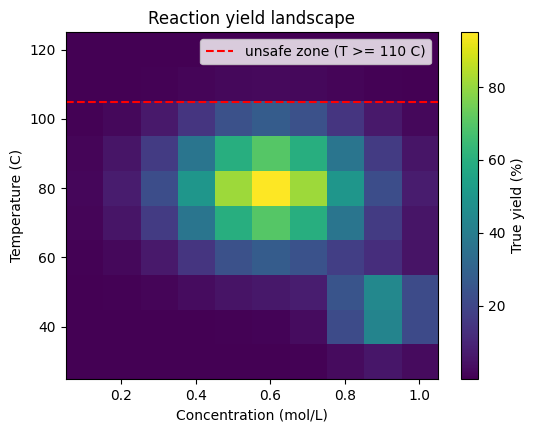

Best possible yield: 95.0% at T=80 C, C=0.6 M


In [3]:
env = SelfDrivingLabEnv(seed=0)
plt.figure(figsize=(6,4.5))
plt.imshow(env.Y, origin="lower", cmap="viridis", aspect="auto",
           extent=[env.C_LEVELS[0]-.05, env.C_LEVELS[-1]+.05, env.T_LEVELS[0]-5, env.T_LEVELS[-1]+5])
plt.colorbar(label="True yield (%)")
plt.axhline(env.UNSAFE_T-5, color="red", ls="--", label="unsafe zone (T >= 110 C)")
plt.xlabel("Concentration (mol/L)"); plt.ylabel("Temperature (C)"); plt.title("Reaction yield landscape"); plt.legend()
plt.savefig("fig1_landscape.png", dpi=200, bbox_inches="tight"); plt.show()
print("Best possible yield: %.1f%% at T=%d C, C=%.1f M" % (env.Y.max(), env.T_LEVELS[np.unravel_index(env.Y.argmax(), env.Y.shape)[0]], env.C_LEVELS[np.unravel_index(env.Y.argmax(), env.Y.shape)[1]]))

## 4. Train the Q-learning agent (5 random seeds) and the baselines

In [4]:
N_SEEDS, EPISODES, EVAL_EVERY = 5, 6000, 100
curves, Qs = [], []
for seed in range(N_SEEDS):
    Q, curve, _ = train_qlearning(episodes=EPISODES, alpha=0.05, gamma=0.9, seed=seed, eval_every=EVAL_EVERY, n_eval=200)
    curves.append(curve); Qs.append(Q); print("seed", seed, "final avg yield %.1f%%" % curve[-5:].mean())
curves = np.array(curves)

# baselines (evaluated with the same protocol: 25 experiments, random starts, 2000 episodes)
base_env = SelfDrivingLabEnv(seed=123)
rand_res = run_policy(base_env, make_random(base_env), 2000)
hill_res = run_policy(base_env, make_hillclimb(base_env), 2000)
q_res = np.mean([run_policy(SelfDrivingLabEnv(seed=500+i), make_greedy(Qs[i]), 2000) for i in range(N_SEEDS)], axis=0)

seed 0 final avg yield 77.5%
seed 1 final avg yield 78.2%
seed 2 final avg yield 80.5%
seed 3 final avg yield 79.2%
seed 4 final avg yield 79.3%


## 5. Learning curve vs baselines

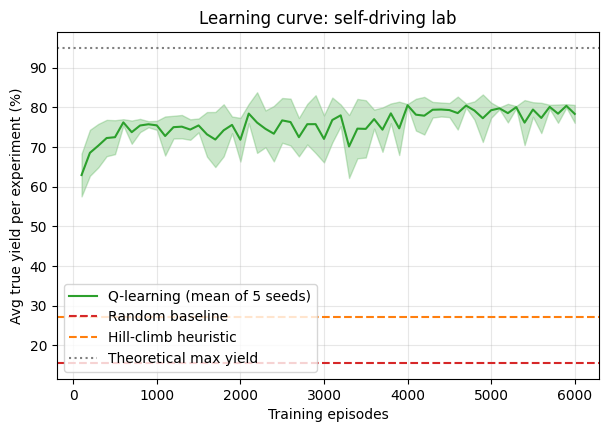

In [5]:
x = np.arange(1, curves.shape[1]+1) * EVAL_EVERY
m, s = curves.mean(0), curves.std(0)
plt.figure(figsize=(7,4.5))
plt.plot(x, m, label="Q-learning (mean of 5 seeds)", color="tab:green"); plt.fill_between(x, m-s, m+s, alpha=0.25, color="tab:green")
plt.axhline(rand_res[0], color="tab:red", ls="--", label="Random baseline")
plt.axhline(hill_res[0], color="tab:orange", ls="--", label="Hill-climb heuristic")
plt.axhline(env.Y.max(), color="gray", ls=":", label="Theoretical max yield")
plt.xlabel("Training episodes"); plt.ylabel("Avg true yield per experiment (%)")
plt.title("Learning curve: self-driving lab"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("fig2_learning_curve.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Results table and bar chart

,Method,Avg yield per experiment (%),Final-experiment yield (%),Best yield found (%),Unsafe experiments (%)
0,Random,15.5,15.4,49.7,20.1
1,Hill-climb heuristic,27.0,31.6,70.0,11.5
2,Q-learning (RL),78.5,85.8,95.0,0.4


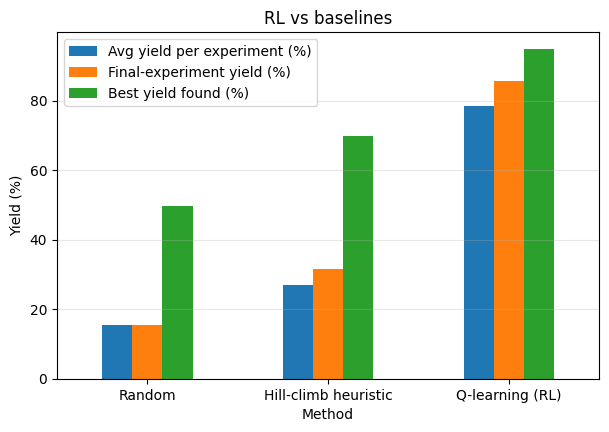

In [6]:
import pandas as pd
df = pd.DataFrame({"Method": ["Random", "Hill-climb heuristic", "Q-learning (RL)"],
    "Avg yield per experiment (%)": [rand_res[0], hill_res[0], q_res[0]],
    "Final-experiment yield (%)": [rand_res[1], hill_res[1], q_res[1]],
    "Best yield found (%)": [rand_res[2], hill_res[2], q_res[2]],
    "Unsafe experiments (%)": [100*rand_res[3], 100*hill_res[3], 100*q_res[3]]}).round(1)
display(df); df.to_csv("results_table.csv", index=False)
ax = df.set_index("Method")[["Avg yield per experiment (%)", "Final-experiment yield (%)", "Best yield found (%)"]].plot.bar(figsize=(7,4.5), rot=0)
ax.set_ylabel("Yield (%)"); ax.set_title("RL vs baselines"); ax.grid(axis="y", alpha=.3)
plt.savefig("fig3_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. What did the agent learn? (policy map + example run)

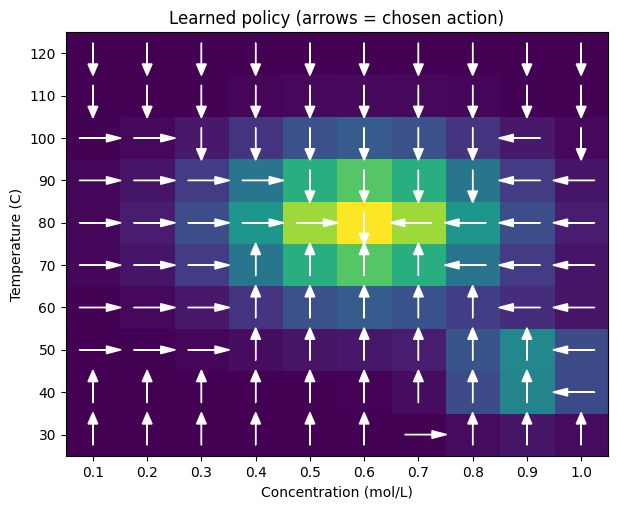

Experiment # | Temp (C) | Conc (M) | True yield (%)
           0 |      120 |      0.7 |            0.1
           1 |      110 |      0.7 |            2.2
           2 |      100 |      0.7 |           23.6
           3 |       90 |      0.7 |           59.5
           4 |       80 |      0.7 |           81.0
           5 |       80 |      0.6 |           95.0
           6 |       70 |      0.6 |           69.8
           7 |       80 |      0.6 |           95.0
           8 |       70 |      0.6 |           69.8
           9 |       80 |      0.6 |           95.0
          10 |       70 |      0.6 |           69.8
          11 |       80 |      0.6 |           95.0
          12 |       70 |      0.6 |           69.8
          13 |       80 |      0.6 |           95.0
          14 |       70 |      0.6 |           69.8
          15 |       80 |      0.6 |           95.0
          16 |       70 |      0.6 |           69.8
          17 |       80 |      0.6 |           95.0
          18

In [7]:
Q = Qs[0]; arrows = {0: (0, 1), 1: (0, -1), 2: (1, 0), 3: (-1, 0)}   # (dx=conc, dy=temp)
fig, ax = plt.subplots(figsize=(7,5.5))
ax.imshow(env.Y, origin="lower", cmap="viridis", aspect="auto", extent=[-.5, 9.5, -.5, 9.5])
for i in range(env.nT):
    for j in range(env.nC):
        dx, dy = arrows[int(np.argmax(Q[i*env.nC+j]))]
        ax.arrow(j-dx*.25, i-dy*.25, dx*.5, dy*.5, head_width=.18, color="white")
ax.set_xticks(range(10)); ax.set_xticklabels(env.C_LEVELS); ax.set_yticks(range(10)); ax.set_yticklabels(env.T_LEVELS)
ax.set_xlabel("Concentration (mol/L)"); ax.set_ylabel("Temperature (C)"); ax.set_title("Learned policy (arrows = chosen action)")
plt.savefig("fig4_policy.png", dpi=200, bbox_inches="tight"); plt.show()

# one example experiment sequence
e = SelfDrivingLabEnv(seed=7); s = e.reset(); path = [(e.T_LEVELS[e.i], e.C_LEVELS[e.j], e.Y[e.i, e.j])]; done = False
while not done:
    s, r, done, info = e.step(int(np.argmax(Q[s]))); path.append((e.T_LEVELS[e.i], e.C_LEVELS[e.j], info["true_yield"]))
print("Experiment # | Temp (C) | Conc (M) | True yield (%)")
for k, (t, c, y) in enumerate(path): print("%12d | %8d | %8.1f | %14.1f" % (k, t, c, y))

## 8. Limitations and ethics (for slide 5)
**Limitations**
- Simulated reaction with a hand-made yield function; real chemistry has many more variables (pH, time, catalyst, mixing).
- Small discrete grid; tabular Q-learning does not scale to many continuous variables (would need DQN/PPO or Bayesian optimisation).
- Q-table is learned for one reaction; it does not transfer to a different reaction without re-training.

**Ethics and safety**
- Real labs can have hazards (exothermic runaway, toxic by-products). The agent must never explore unsafe settings in hardware - we penalise unsafe zones, but a real lab needs hard safety constraints, simulation-first training and human oversight.
- Reproducibility and transparency: log all experiments; scientists remain responsible for the conclusions.
- Automation may change the roles of lab technicians - treat the system as an assistant, not a replacement.

## 9. Conclusion
The RL agent learned to move from any starting recipe to the high-yield region (~80 C, ~0.6 M), avoided the unsafe zone and the decoy local optimum, and clearly beat random and heuristic experiment selection.